In [42]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn
import numpy as np

In [43]:
test = pd.read_csv("train_Diamonds.csv")
test.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,2.01,Good,F,SI2,58.1,64.0,16231,8.23,8.19,4.77
1,1.01,Very Good,E,SI2,60.0,60.0,4540,6.57,6.49,3.92
2,1.10,Premium,H,VS2,62.5,58.0,5729,6.59,6.54,4.10
3,1.50,Good,E,SI2,61.5,65.0,6300,7.21,7.17,4.42
4,1.52,Very Good,G,VS1,62.1,57.0,12968,7.27,7.32,4.53


In [44]:
train = pd.read_csv("train_Diamonds.csv")
train.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,2.01,Good,F,SI2,58.1,64.0,16231,8.23,8.19,4.77
1,1.01,Very Good,E,SI2,60.0,60.0,4540,6.57,6.49,3.92
2,1.10,Premium,H,VS2,62.5,58.0,5729,6.59,6.54,4.10
3,1.50,Good,E,SI2,61.5,65.0,6300,7.21,7.17,4.42
4,1.52,Very Good,G,VS1,62.1,57.0,12968,7.27,7.32,4.53


In [45]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43152 entries, 0 to 43151
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    43152 non-null  float64
 1   cut      43152 non-null  object 
 2   color    43152 non-null  object 
 3   clarity  43152 non-null  object 
 4   depth    43152 non-null  float64
 5   table    43152 non-null  float64
 6   price    43152 non-null  int64  
 7   x        43152 non-null  float64
 8   y        43152 non-null  float64
 9   z        43152 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 3.3+ MB


In [46]:
train.describe(include="all")

,carat,cut,color,clarity,depth,table,price,x,y,z
count,43152.000000,43152,43152,43152,43152.000000,43152.000000,43152.000000,43152.000000,43152.000000,43152.000000
unique,NaN,5,7,8,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Ideal,G,SI1,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,17259,9015,10520,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.798233,NaN,NaN,NaN,61.743046,57.459548,3939.490707,5.732607,5.736434,3.539256
std,0.473342,NaN,NaN,NaN,1.428243,2.229325,3990.000962,1.120196,1.147500,0.708062
min,0.200000,NaN,NaN,NaN,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,NaN,NaN,NaN,61.000000,56.000000,956.000000,4.720000,4.730000,2.910000
50%,0.700000,NaN,NaN,NaN,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,NaN,NaN,NaN,62.500000,59.000000,5354.250000,6.540000,6.540000,4.040000


In [47]:
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [48]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [49]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [50]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['object']).columns
    
for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

In [51]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

In [52]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

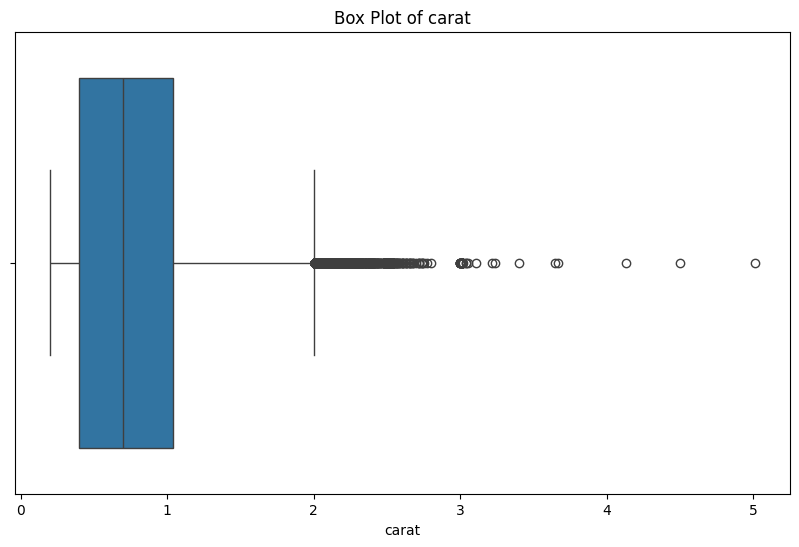

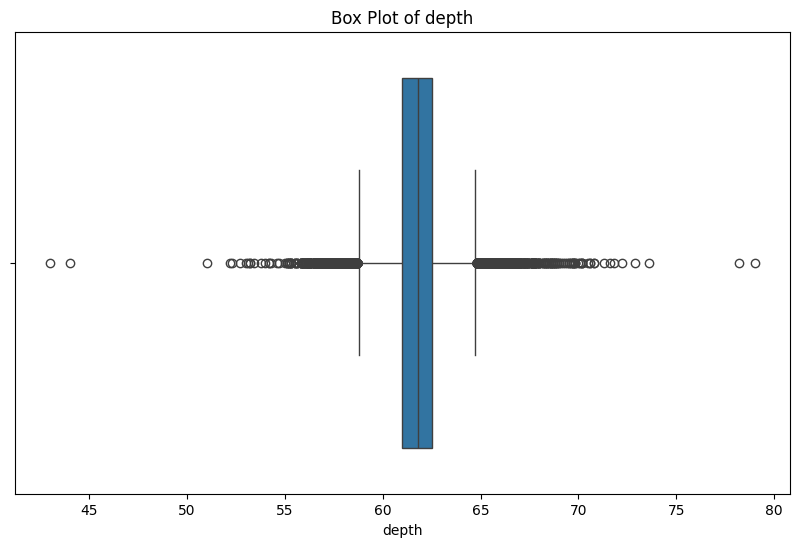

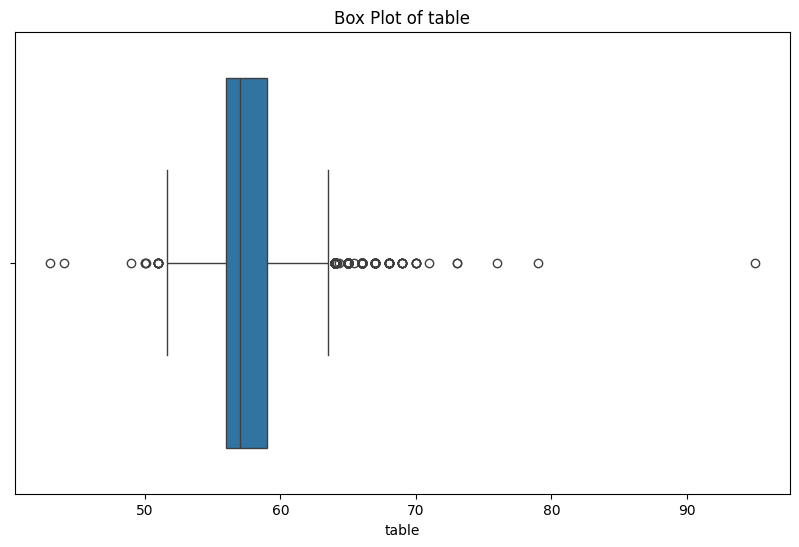

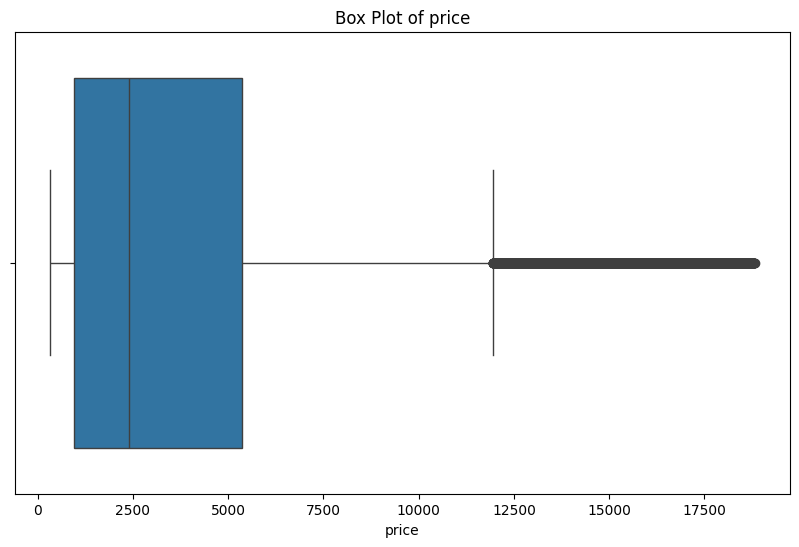

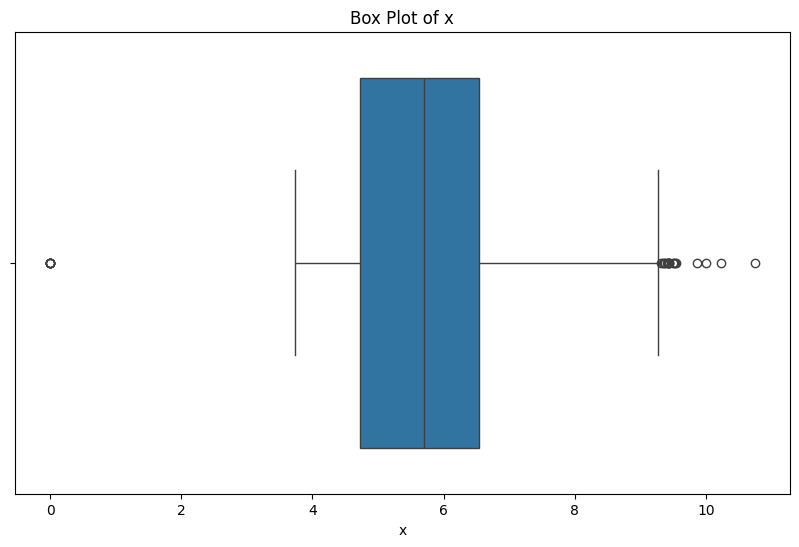

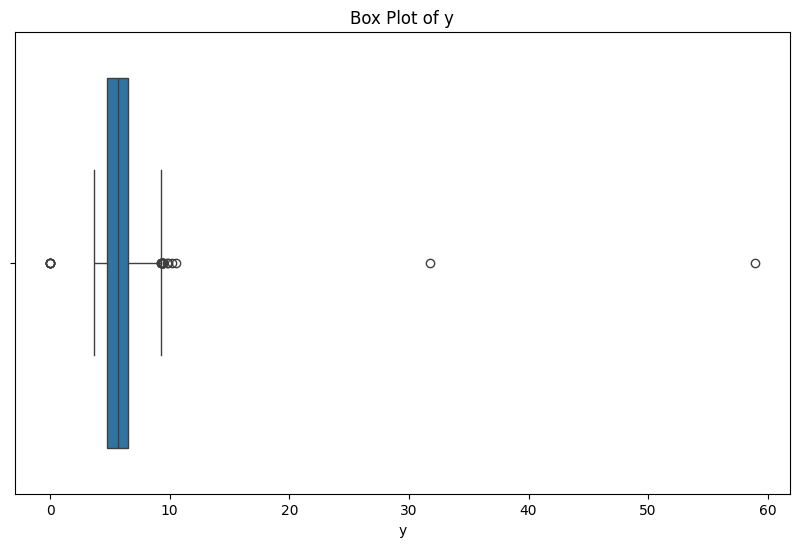

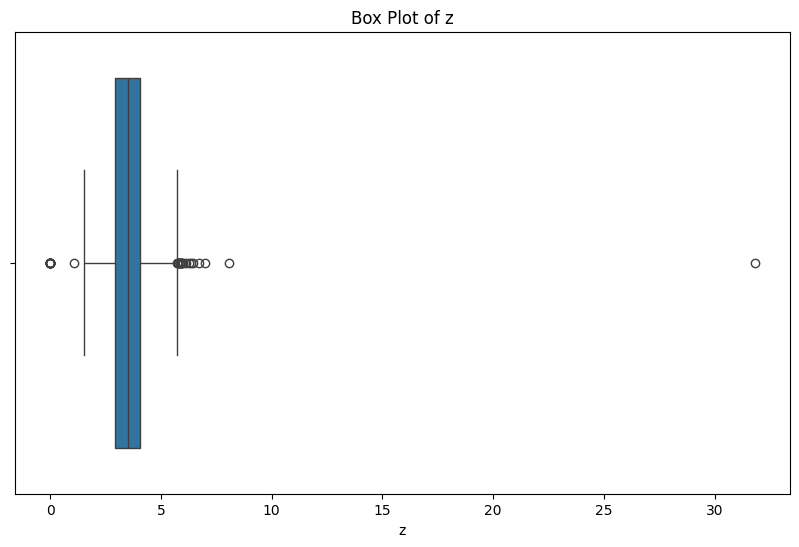

In [53]:
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [54]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [55]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 *IQR)) | (df[numeric_features] > (Q3 + 1.5* IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

In [56]:
'''
median = df['column_name'].median()
df['column_name'] = df['column_name'].apply(lambda x: median if x < (Q1 - 1.5 IQR) or x > (Q3 + 1.5 IQR) else x)
'''

"\nmedian = df['column_name'].median()\ndf['column_name'] = df['column_name'].apply(lambda x: median if x < (Q1 - 1.5 IQR) or x > (Q3 + 1.5 IQR) else x)\n"

In [57]:
'''
# Mengganti outlier dengan nilai batas terdekat
df['column_name'] = df['column_name'].apply(lambda x: (Q1 - 1.5  IQR) if x < lower_bound else (Q3 + 1.5  IQR) if x > (Q3 + 1.5 * IQR) else x)
'''

"\n# Mengganti outlier dengan nilai batas terdekat\ndf['column_name'] = df['column_name'].apply(lambda x: (Q1 - 1.5 \xa0IQR) if x < lower_bound else (Q3 + 1.5\xa0 IQR) if x > (Q3 + 1.5 * IQR) else x)\n"

In [58]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

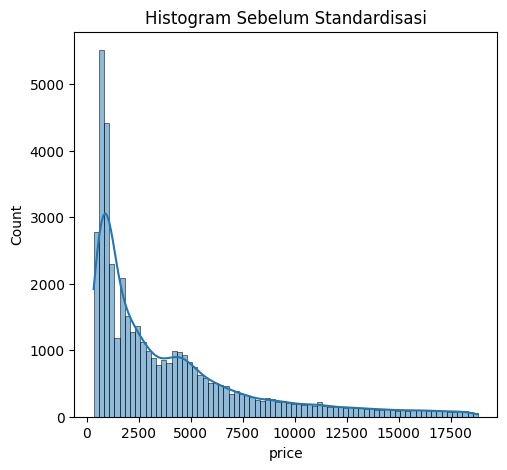

In [59]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

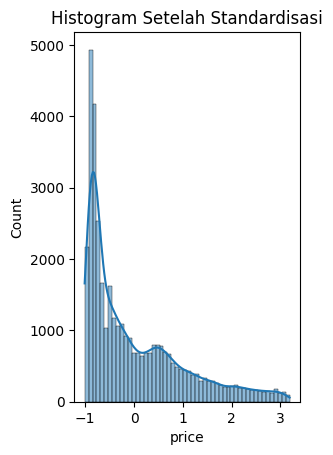

In [60]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [61]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()
print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
          carat     depth     table     price         x         y         z  \
2393  -0.376568  0.650256 -1.618269 -0.747301 -0.204125 -0.261870 -0.165390   
3481   0.781870  1.011655 -0.627576  0.117529  0.786165  0.765186  0.890727   
4744  -1.050078  1.011655 -0.627576 -0.874567 -1.173996 -1.206762 -1.105995   
6627   0.889631  0.198506 -0.132230  0.234672  1.000558  0.939785  0.989738   
10152 -0.807614 -0.072543 -0.627576 -0.635582 -0.796257 -0.775398 -0.792460   
...         ...       ...       ...       ...       ...       ...       ...   
41727 -0.511270  0.017806 -1.122922 -0.471076 -0.398099 -0.374846 -0.379914   
42175  1.401499  0.017806 -0.627576  0.672872  1.347669  1.288984  1.319775   
42263 -0.565150  1.011655  0.363116 -0.769356 -0.500191 -0.559716 -0.429420   
42455 -0.484329 -1.698841  0.363116 -0.774056 -0.244961 -0.292682 -0.429420   
42807  2.155830  0.379206  0.363116  2.982461  1.807082  1.761430  1.831331   

           cut color clarity  
2393

In [62]:
# Menghapus baris duplikat
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
          carat     depth     table     price         x         y         z  \
1      0.808810 -1.608492  1.353809  0.511620  1.041394  0.960326  0.808218   
2      1.051274  0.650256  0.363116  0.941505  1.061813  1.011679  1.105251   
5     -0.403508 -1.879541  0.858463 -0.346341 -0.142870 -0.210517 -0.363412   
6     -1.103958  0.108156 -1.122922 -0.753448 -1.255669 -1.247844 -1.238009   
7     -0.484329  0.017806 -0.627576 -0.548810 -0.347053 -0.385117 -0.363412   
...         ...       ...       ...       ...       ...       ...       ...   
43147  0.916572  0.559906  0.858463  0.668895  0.949512  0.980868  1.022742   
43148 -0.645972 -0.704993 -1.122922 -0.545194 -0.530818 -0.559716 -0.610940   
43149 -1.023137 -1.337442  0.363116 -0.763210 -1.082113 -1.124597 -1.205006   
43150  0.512466  0.921305  0.858463 -0.091809  0.592191  0.487881  0.643199   
43151  1.159035 -1.247092  0.363116  1.155181  1.296624  1.268443  1.121753   

             

In [63]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

,cut,color,clarity
1,Very Good,E,SI2
2,Premium,H,VS2
5,Premium,G,VVS1
6,Ideal,F,VVS1
7,Ideal,G,VS2
...,...,...,...
43147,Very Good,I,VS2
43148,Ideal,D,VS1
43149,Very Good,F,IF
43150,Premium,J,SI1


In [64]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,carat,depth,table,price,x,y,z,cut_Fair,cut_Good,cut_Ideal,...,color_I,color_J,clarity_I1,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
1,0.808810,-1.608492,1.353809,0.511620,1.041394,0.960326,0.808218,False,False,False,...,False,False,False,False,False,True,False,False,False,False
2,1.051274,0.650256,0.363116,0.941505,1.061813,1.011679,1.105251,False,False,False,...,False,False,False,False,False,False,False,True,False,False
5,-0.403508,-1.879541,0.858463,-0.346341,-0.142870,-0.210517,-0.363412,False,False,False,...,False,False,False,False,False,False,False,False,True,False
6,-1.103958,0.108156,-1.122922,-0.753448,-1.255669,-1.247844,-1.238009,False,False,True,...,False,False,False,False,False,False,False,False,True,False
7,-0.484329,0.017806,-0.627576,-0.548810,-0.347053,-0.385117,-0.363412,False,False,True,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43147,0.916572,0.559906,0.858463,0.668895,0.949512,0.980868,1.022742,False,False,False,...,True,False,False,False,False,False,False,True,False,False
43148,-0.645972,-0.704993,-1.122922,-0.545194,-0.530818,-0.559716,-0.610940,False,False,True,...,False,False,False,False,False,False,True,False,False,False
43149,-1.023137,-1.337442,0.363116,-0.763210,-1.082113,-1.124597,-1.205006,False,False,False,...,False,False,False,True,False,False,False,False,False,False
43150,0.512466,0.921305,0.858463,-0.091809,0.592191,0.487881,0.643199,False,False,False,...,False,True,False,False,True,False,False,False,False,False


In [65]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil
df_lencoder

,carat,depth,table,price,x,y,z,cut,color,clarity
1,0.808810,-1.608492,1.353809,0.511620,1.041394,0.960326,0.808218,4,1,3
2,1.051274,0.650256,0.363116,0.941505,1.061813,1.011679,1.105251,3,4,5
5,-0.403508,-1.879541,0.858463,-0.346341,-0.142870,-0.210517,-0.363412,3,3,6
6,-1.103958,0.108156,-1.122922,-0.753448,-1.255669,-1.247844,-1.238009,2,2,6
7,-0.484329,0.017806,-0.627576,-0.548810,-0.347053,-0.385117,-0.363412,2,3,5
...,...,...,...,...,...,...,...,...,...,...
43147,0.916572,0.559906,0.858463,0.668895,0.949512,0.980868,1.022742,4,5,5
43148,-0.645972,-0.704993,-1.122922,-0.545194,-0.530818,-0.559716,-0.610940,2,0,4
43149,-1.023137,-1.337442,0.363116,-0.763210,-1.082113,-1.124597,-1.205006,4,2,1
43150,0.512466,0.921305,0.858463,-0.091809,0.592191,0.487881,0.643199,3,6,2


In [66]:
df_lencoder.head()

,carat,depth,table,price,x,y,z,cut,color,clarity
1,0.808810,-1.608492,1.353809,0.511620,1.041394,0.960326,0.808218,4,1,3
2,1.051274,0.650256,0.363116,0.941505,1.061813,1.011679,1.105251,3,4,5
5,-0.403508,-1.879541,0.858463,-0.346341,-0.142870,-0.210517,-0.363412,3,3,6
6,-1.103958,0.108156,-1.122922,-0.753448,-1.255669,-1.247844,-1.238009,2,2,6
7,-0.484329,0.017806,-0.627576,-0.548810,-0.347053,-0.385117,-0.363412,2,3,5


In [67]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0]  # Menampilkan kolom dengan missing values

,Missing Values,Percentage


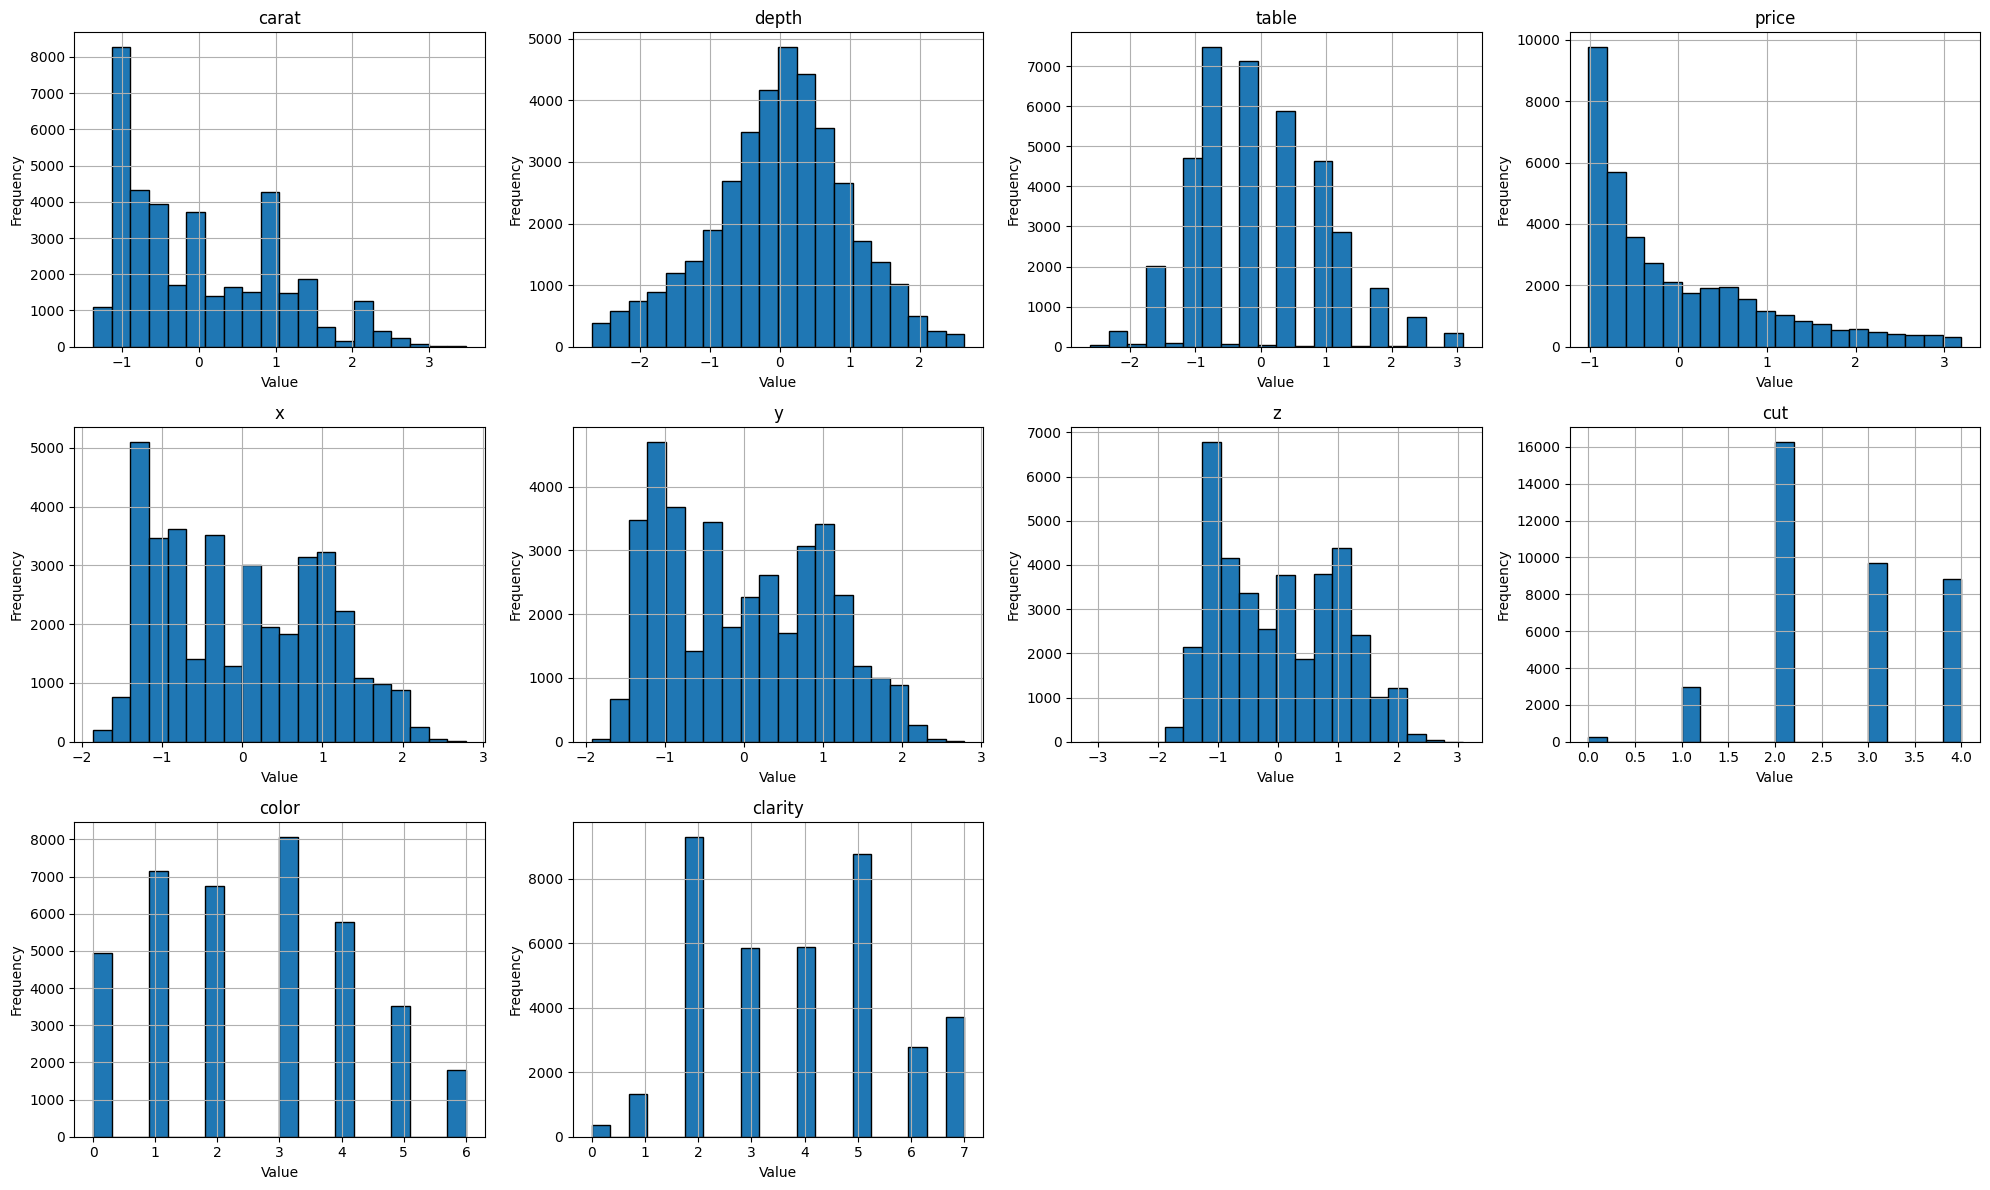

In [68]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4  # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols)  # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()
    
# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')
    
# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()


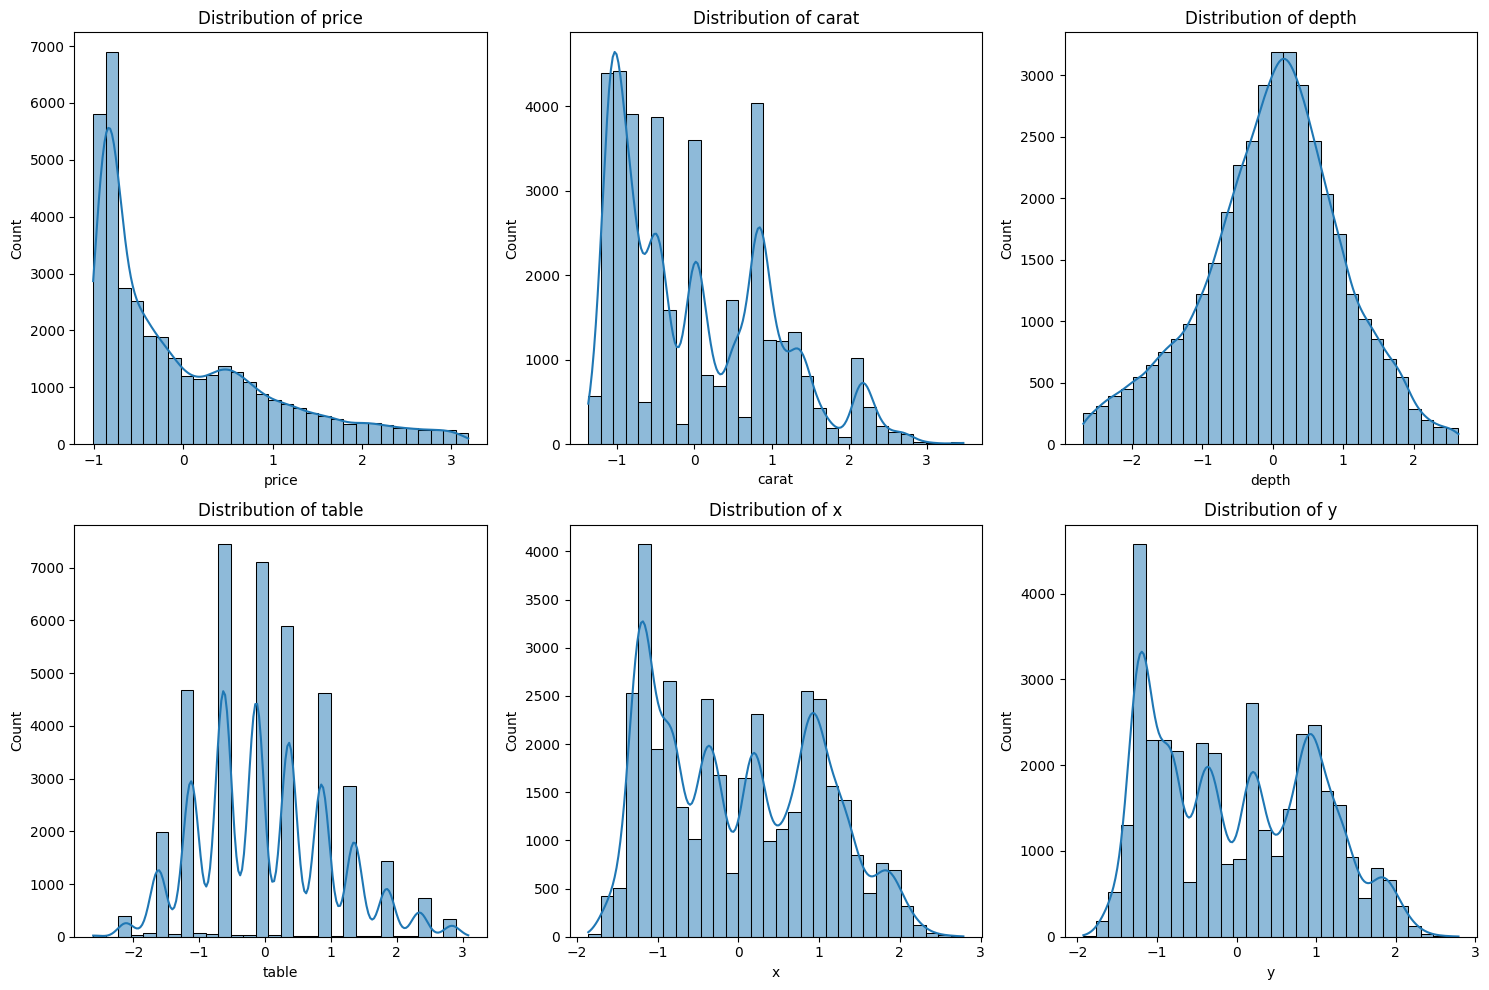

In [69]:
# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = ['price', 'carat', 'depth', 'table', 'x', 'y']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')
    
plt.tight_layout()
plt.show()

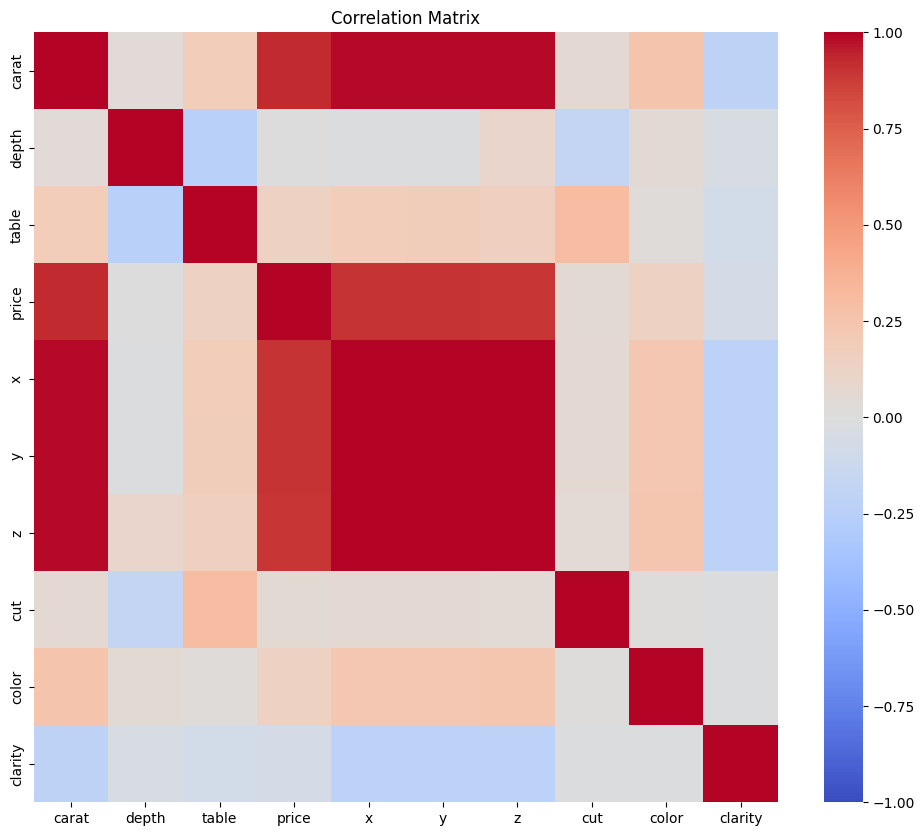

In [70]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()


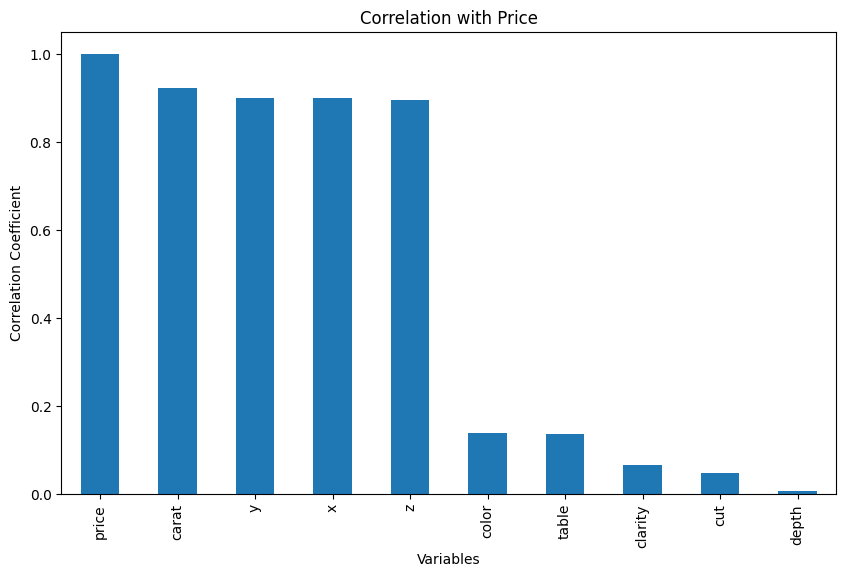

In [71]:
# Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['price']
# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with Price')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

In [72]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=['price'])
y = df_lencoder['price']

In [73]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [74]:
# menghitung panjang/jumlah data 
print("Jumlah data: ",len(X))
# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ",len(x_test))

Jumlah data:  37986
Jumlah data latih:  30388
Jumlah data test:  7598


In [75]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# 1. Pemisahan Fitur dan Target
X = df_one_hot.drop(columns=['price'])
y = df_one_hot['price']

# Split data latih (80%) dan data uji (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Inisialisasi Model (Decision Tree, Random Forest, KNN)
models = {
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=5)
}

# 3. Pelatihan & Evaluasi Model
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

# 4. Tampilkan Tabel Hasil Perbandingan
results_df = pd.DataFrame(results)
print(results_df.sort_values(by="R2 Score", ascending=False).to_string(index=False))

        Model      MAE     RMSE  R2 Score
Random Forest 0.072904 0.134204  0.982307
Decision Tree 0.099421 0.184361  0.966610
KNN Regressor 0.112351 0.197151  0.961816


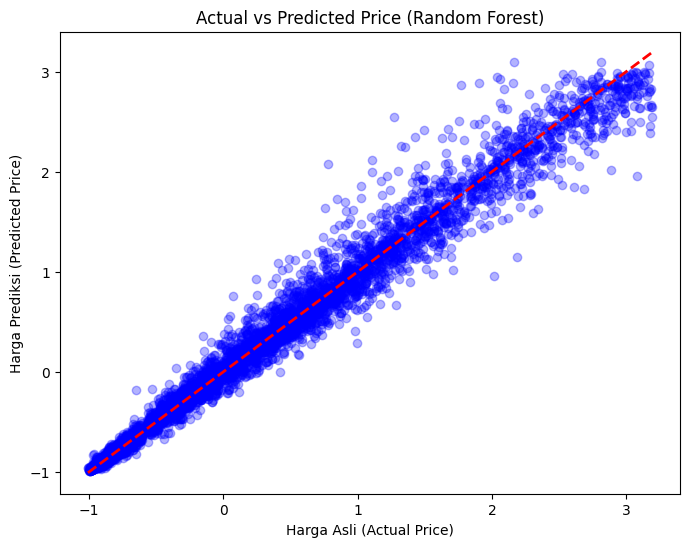

In [76]:
best_model = models["Random Forest"]
y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Harga Asli (Actual Price)')
plt.ylabel('Harga Prediksi (Predicted Price)')
plt.title('Actual vs Predicted Price (Random Forest)')
plt.show()

C:\Users\ramli\AppData\Local\Temp\ipykernel_18644\1096428977.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Model", y="R2 Score", data=results_df, palette="magma")


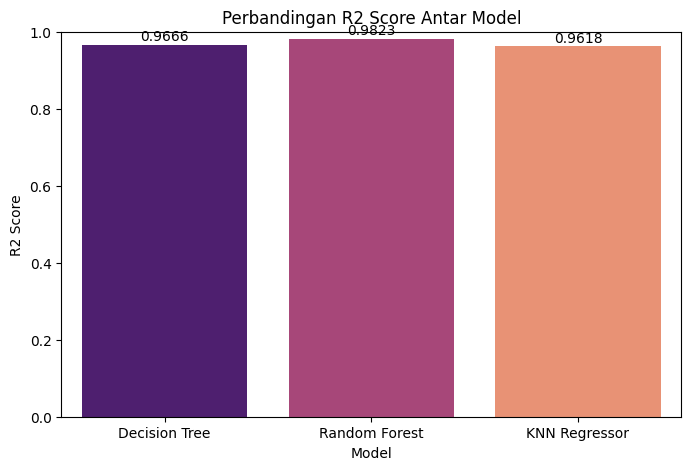

In [77]:
# Visualisasi R2 Score
plt.figure(figsize=(8, 5))
sns.barplot(x="Model", y="R2 Score", data=results_df, palette="magma")
plt.title("Perbandingan R2 Score Antar Model")
plt.ylim(0, 1)
for index, row in results_df.iterrows():
    plt.text(index, row['R2 Score'] + 0.01, f"{row['R2 Score']:.4f}", ha='center')
plt.show()

In [78]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBR, 'prediction_diamonds_model.joblib')  

['prediction_diamonds_model.joblib']